# Продажи, регионы и доставка

Покупательские когорты: январь 2017–июль 2018. Валюта BRL. Стоимость товаров доставленных заказов не равна доходу платформы.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'scripts'))
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)


In [2]:
from build_analysis import load_fact, START, END
fact=load_fact()
cohort=fact.loc[fact.order_purchase_timestamp.ge(START)&fact.order_purchase_timestamp.lt(END)].copy()
monthly=pd.read_csv(ROOT/'reports/tables/monthly.csv',parse_dates=['purchase_month'])
states=pd.read_csv(ROOT/'reports/tables/states.csv')
categories=pd.read_csv(ROOT/'reports/tables/categories.csv')
print('Всего заказов в витрине:',len(fact),'В выбранном периоде:',len(cohort))
display(pd.read_csv(ROOT/'reports/tables/month_coverage.csv'))


Всего заказов в витрине: 99441 В выбранном периоде: 92580


,purchase_month,orders,first_day,last_day,in_reporting_period
0,2016-09-01,4,2016-09-04 21:15:19,2016-09-15 12:16:38,False
1,2016-10-01,324,2016-10-02 22:07:52,2016-10-22 08:25:27,False
2,2016-12-01,1,2016-12-23 23:16:47,2016-12-23 23:16:47,False
3,2017-01-01,800,2017-01-05 11:56:06,2017-01-31 23:37:58,True
4,2017-02-01,1780,2017-02-01 00:04:17,2017-02-28 23:47:08,True
5,2017-03-01,2682,2017-03-01 00:01:30,2017-03-31 23:54:45,True
6,2017-04-01,2404,2017-04-01 00:54:10,2017-04-30 23:48:13,True
7,2017-05-01,3700,2017-05-01 01:18:22,2017-05-31 22:59:52,True
8,2017-06-01,3245,2017-06-01 00:05:38,2017-06-30 23:20:08,True
9,2017-07-01,4026,2017-07-01 00:04:15,2017-07-31 23:55:27,True


## Динамика

Заказы группируются по месяцу покупки. Для сравнения лет берём одинаковые месяцы, а не весь 2017 против части 2018.

,purchase_month,delivered_orders,delivered_gmv,average_order_value,gmv_mom
0,2017-01-01,750,111798.36,149.064480,NaN
1,2017-02-01,1653,234223.40,141.695947,1.095052
2,2017-03-01,2546,359198.85,141.083602,0.533574
3,2017-04-01,2303,340669.68,147.924307,-0.051585
4,2017-05-01,3546,489338.25,137.997250,0.436401
5,2017-06-01,3135,421923.37,134.584807,-0.137767
6,2017-07-01,3872,481604.52,124.381333,0.141450
7,2017-08-01,4193,554699.70,132.291844,0.151774
8,2017-09-01,4150,607399.67,146.361366,0.095006
9,2017-10-01,4478,648247.65,144.762762,0.067251


GMV Jan-Jul YoY: 161.6%


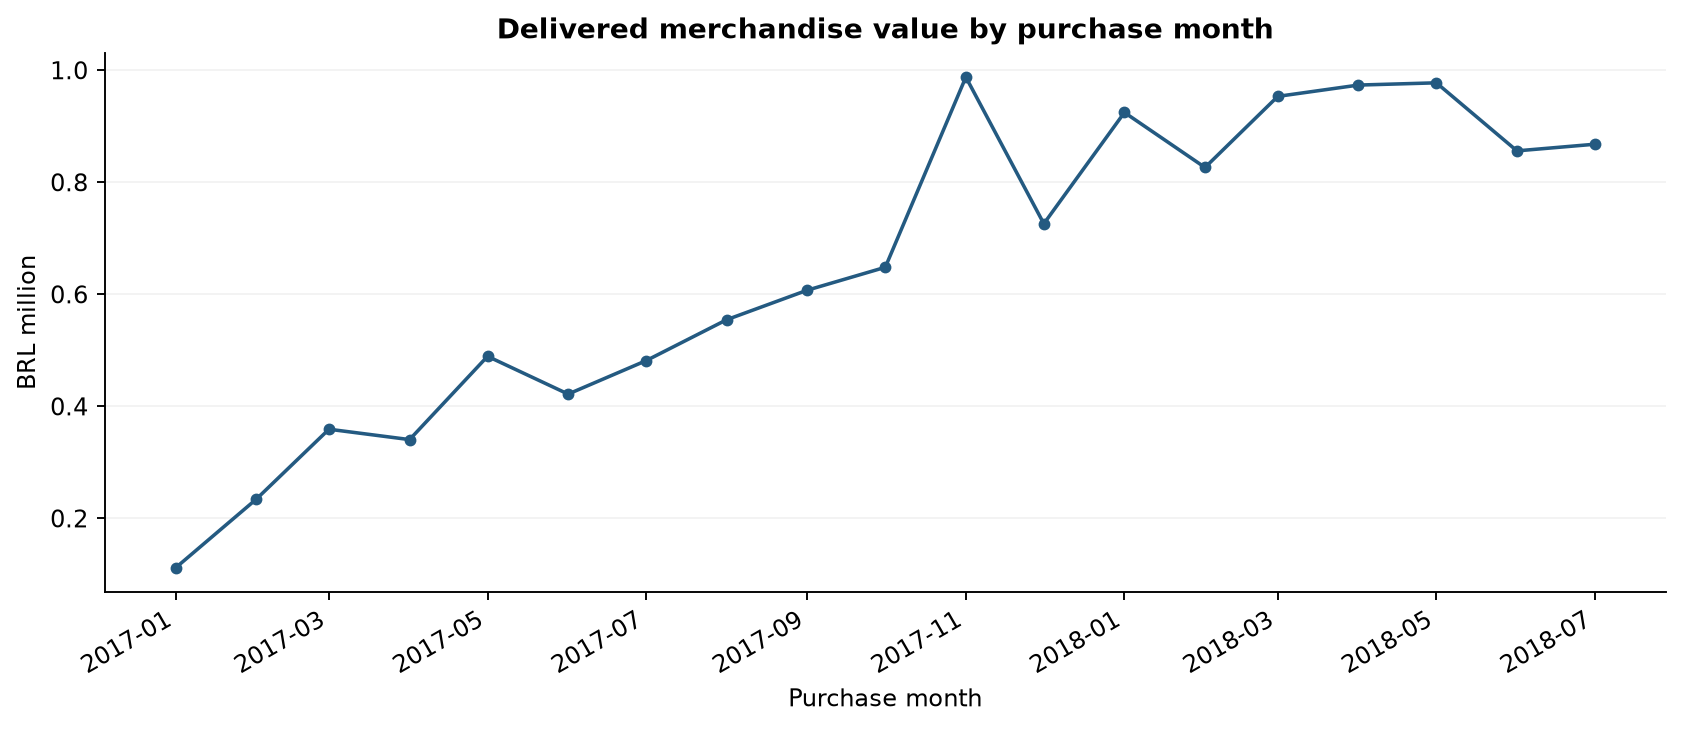

In [3]:
display(monthly[['purchase_month','delivered_orders','delivered_gmv','average_order_value','gmv_mom']])
jan_jul=monthly.loc[monthly.purchase_month.dt.month.le(7)].groupby(monthly.purchase_month.dt.year).delivered_gmv.sum()
print('GMV Jan-Jul YoY:',f'{jan_jul.loc[2018]/jan_jul.loc[2017]-1:.1%}')
display(Image(filename=str(ROOT/'reports/figures/01_monthly_gmv.png')))


## Доставка

Опоздание определяется календарными датами. Заказы с неизвестной датой получения не считаются своевременными.

Доставлено: 89860 Пригодно для доставки: 89852
Исключено: 8
Опоздавших: 6138 Доля: 6.83%
Сроки, дни: {0.5: 10.615949074074074, 0.9: 23.60765393518522, 0.99: 46.559865509259375}


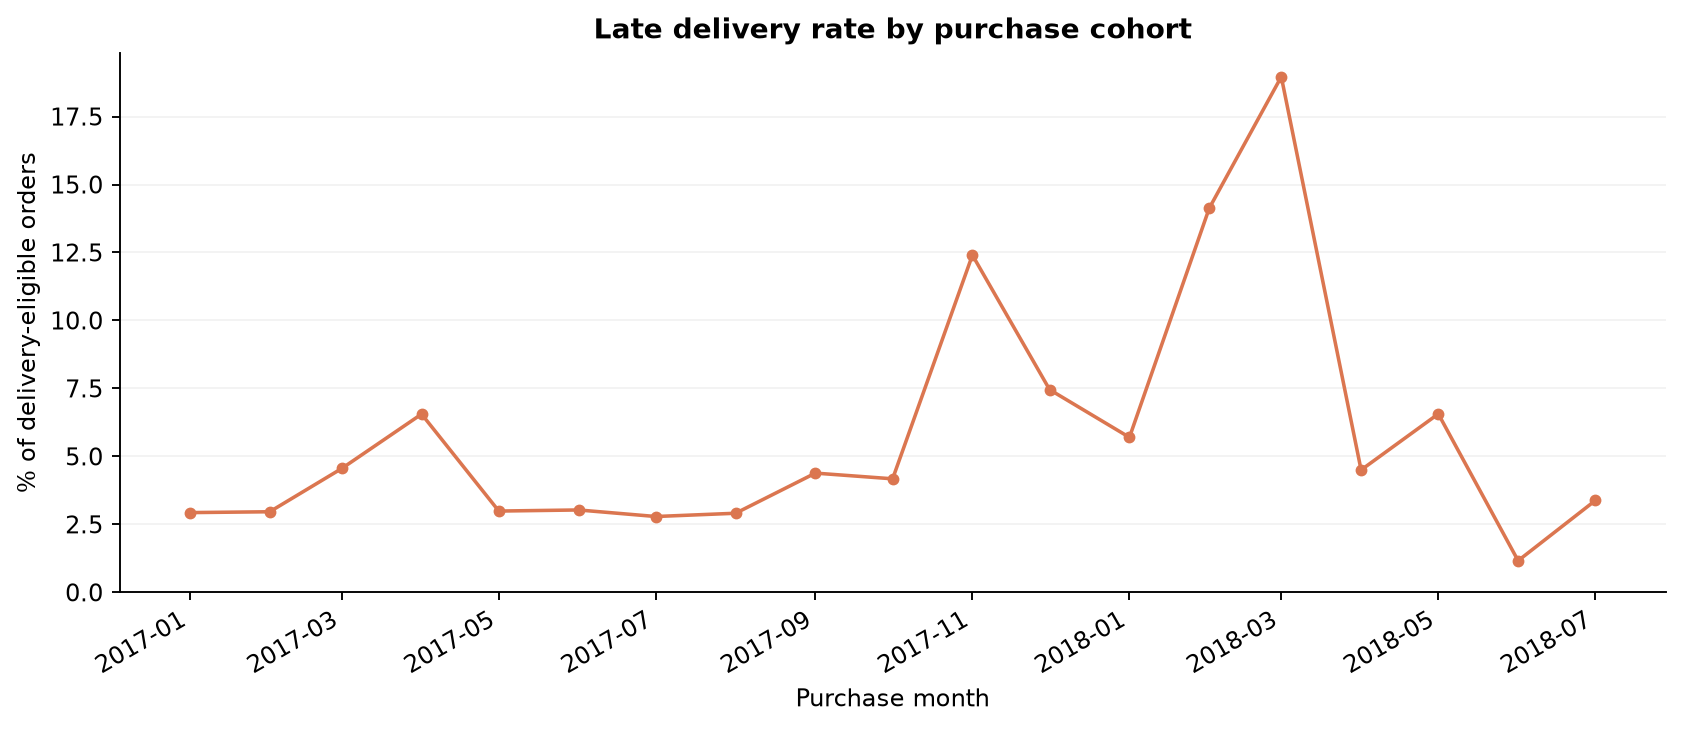

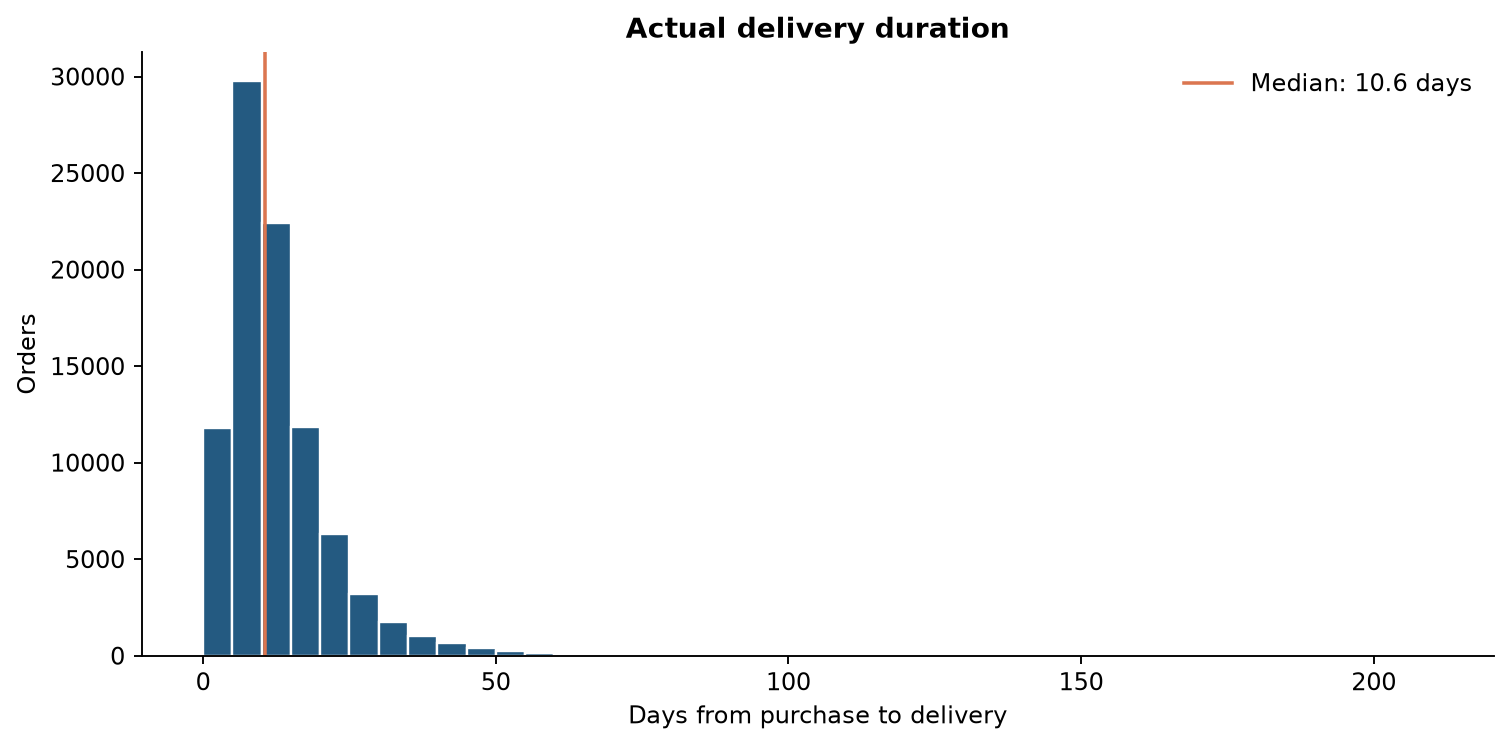

In [4]:
eligible=cohort.loc[cohort.delivery_eligible.fillna(False)]
delivered=cohort.loc[cohort.order_status.eq('delivered')]
print('Доставлено:',len(delivered),'Пригодно для доставки:',len(eligible))
print('Исключено:',len(delivered)-len(eligible))
print('Опоздавших:',int(eligible.is_late.sum()),'Доля:',f'{eligible.is_late.mean():.2%}')
print('Сроки, дни:',eligible.delivery_days.quantile([.5,.9,.99]).to_dict())
display(Image(filename=str(ROOT/'reports/figures/02_monthly_late_rate.png')))
display(Image(filename=str(ROOT/'reports/figures/06_delivery_distribution.png')))


## Регионы

Объём проблем и доля проблем отвечают на разные вопросы. Порог 300 пригодных заказов здесь используется только для описательного сравнения долей; интервалы Wilson показывают неопределённость.

,customer_state,delivery_eligible,late_orders,late_rate,late_ci_low,late_ci_high
0,SP,37235,1532,0.041144,0.039174,0.043209
1,RJ,11587,1453,0.125399,0.119493,0.131554
2,MG,10619,507,0.047745,0.043850,0.051966
3,BA,3094,395,0.127666,0.116367,0.139889
4,RS,5034,316,0.062773,0.056400,0.069813
5,SC,3336,285,0.085432,0.076417,0.095400
6,ES,1889,214,0.113287,0.099773,0.128372
7,PR,4576,189,0.041302,0.035911,0.047463
8,CE,1218,176,0.144499,0.125871,0.165363
9,PE,1504,149,0.099069,0.084977,0.115205


,customer_state,all_orders,delivered_orders,delivered_gmv,delivered_freight,delivery_eligible,late_orders,delivery_days_sum,reviewed_orders,low_reviews,late_rate,average_order_value,mean_delivery_days,low_review_rate,late_ci_low,late_ci_high,late_excess_vs_overall
14,AL,395,380,76552.45,14629.73,380,85,9481.554873,377,82,0.223684,201.453816,24.951460,0.217507,0.184670,0.268229,59.041312
11,MA,713,684,112160.82,29443.85,684,123,14987.132998,680,139,0.179825,163.977807,21.911013,0.204412,0.152857,0.210368,76.274362
19,SE,324,309,51730.70,12611.72,309,51,6827.988519,308,60,0.165049,167.413269,22.097050,0.194805,0.127820,0.210503,29.891488
15,PI,472,455,81587.77,19479.47,455,66,8996.487847,450,73,0.145055,179.313780,19.772501,0.162222,0.115668,0.180385,34.917887
8,CE,1271,1218,208650.66,44019.16,1218,176,26311.676424,1212,215,0.144499,171.305961,21.602362,0.177393,0.125871,0.165363,92.795575
3,BA,3211,3094,472225.41,92495.80,3094,395,61063.880243,3067,535,0.127666,152.626183,19.736225,0.174438,0.116367,0.139889,183.641633
1,RJ,12047,11587,1657663.30,277483.43,11587,1453,182311.229340,11453,2148,0.125399,143.062337,15.734118,0.187549,0.119493,0.131554,661.464965
13,PA,927,899,164454.21,35320.37,899,106,21780.971030,886,163,0.117909,182.930156,24.227999,0.183973,0.098435,0.140634,44.587210
6,ES,1924,1889,251336.62,45975.57,1889,214,30386.981366,1863,263,0.113287,133.052737,16.086279,0.141170,0.099773,0.128372,84.957998
18,PB,505,488,104867.29,23760.88,488,52,10147.534560,483,73,0.106557,214.891988,20.794128,0.151139,0.082189,0.137071,18.663580


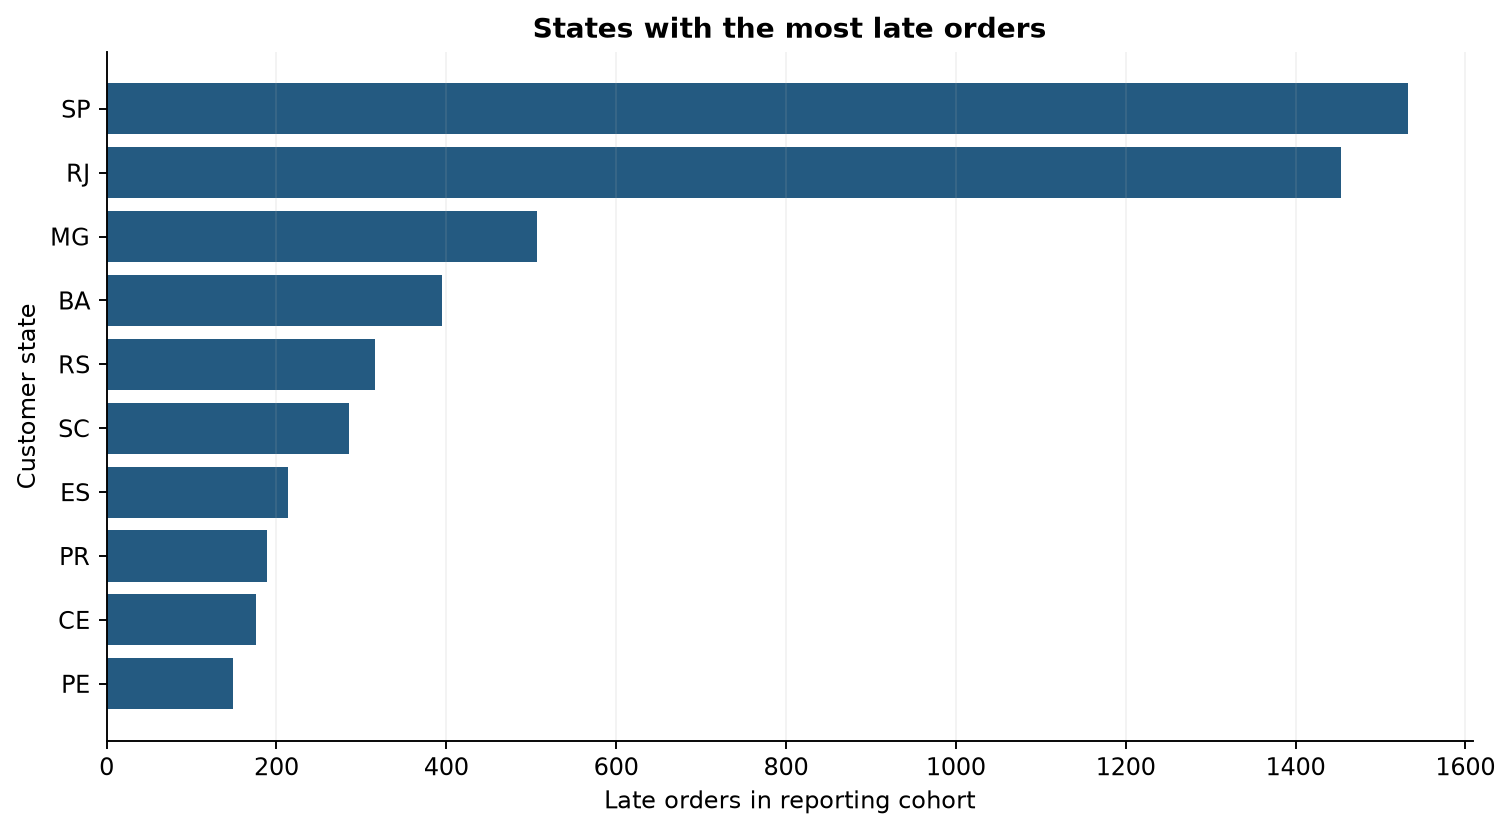

In [5]:
display(states[['customer_state','delivery_eligible','late_orders','late_rate','late_ci_low','late_ci_high']].head(10))
display(states.loc[states.delivery_eligible.ge(300)].sort_values('late_rate',ascending=False).head(10))
display(Image(filename=str(ROOT/'reports/figures/03_state_late_orders.png')))


## Категории

Суммы GMV категорий складываются. Числа заказов по категориям не складываются: один заказ может включать несколько категорий.

,category,item_count,orders_with_category,delivered_gmv,delivered_freight,gmv_share,cumulative_gmv_share
0,health_beauty,8587,7845,1110166.49,161948.78,0.089947,0.089947
1,watches_gifts,5444,5104,1093698.85,91029.72,0.088613,0.178560
2,bed_bath_table,10290,8712,962064.68,187529.68,0.077948,0.256507
3,sports_leisure,7943,7081,901980.22,154115.48,0.073080,0.329587
4,computers_accessories,7217,6138,848002.95,135972.12,0.068706,0.398293
5,furniture_decor,7665,5917,665068.62,156638.90,0.053885,0.452178
6,cool_stuff,3592,3436,593363.11,78621.32,0.048075,0.500253
7,housewares,6167,5185,555578.26,128711.64,0.045014,0.545266
8,auto,3762,3457,532805.81,82653.32,0.043169,0.588435
9,garden_tools,4127,3323,452820.70,92621.70,0.036688,0.625123


Доля десяти крупнейших категорий: 62.5%


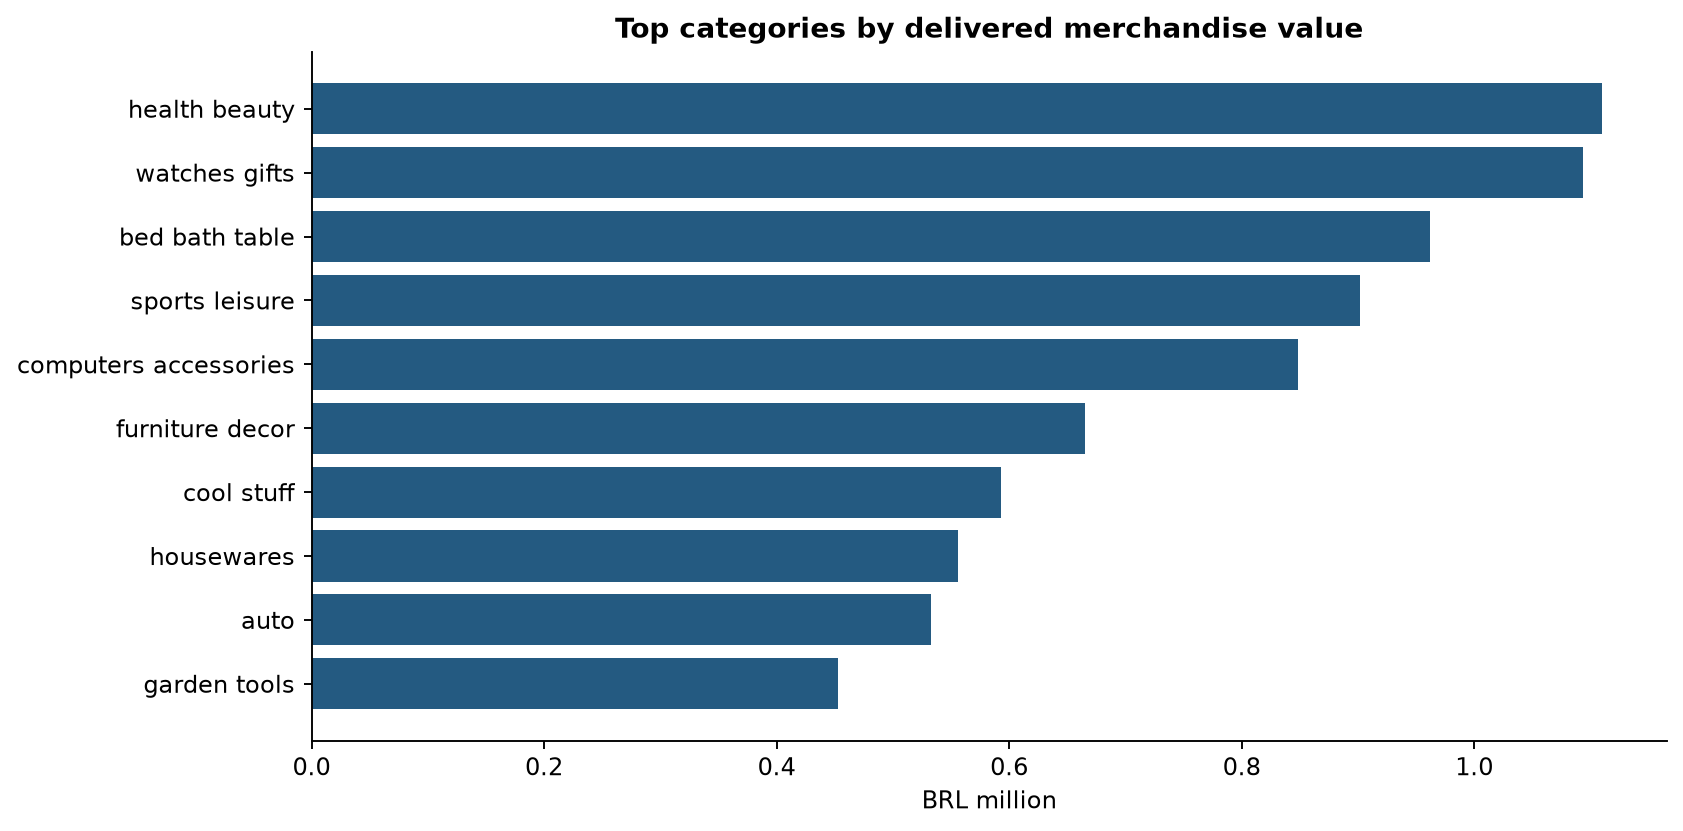

In [6]:
display(categories.head(10))
print('Доля десяти крупнейших категорий:',f'{categories.head(10).gmv_share.sum():.1%}')
display(Image(filename=str(ROOT/'reports/figures/04_categories_gmv.png')))


## Контроль воспроизводимости

Независимые сверки SQL с raw CSV на уровне каждого заказа и итоговых агрегатов.

In [7]:
import json
validation=json.loads((ROOT/'reports/validation.json').read_text(encoding='utf-8'))
display(pd.DataFrame(validation['checks']))
assert all(row['passed'] for row in validation['checks'])


,check,passed,detail
0,one_row_per_order,True,99441
1,same_order_ids,True,raw vs SQL
2,item_gmv_per_order,True,Independent per-order raw aggregation
3,freight_value_per_order,True,Independent per-order raw aggregation
4,payment_value_per_order,True,Independent per-order raw aggregation
5,latest_review_selection,True,Latest answer timestamp; then creation date an...
6,cohort_orders,True,SQL aggregate=92580; fact=92580
7,delivered_orders,True,SQL aggregate=89860; fact=89860
8,eligible_delivery,True,SQL aggregate=89852; fact=89852
9,late_orders,True,SQL aggregate=6138; fact=6138


## Выводы

Конкретные числа и рекомендации: reports/business_report.md. Ни региональные различия, ни динамика продаж не доказывают причину наблюдений. Отдельная статистическая проверка разобрана в следующем ноутбуке.